# Figure S5: block-level feature-ablation analysis

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare, rankdata, wilcoxon

from manuscript_analysis.contract import N_RUNS
from manuscript_analysis.figures.ablation_forest import (
    FAMILY_ALPHA, _reuse_matched_three_baseline, draw_ablation_forest_figure, permutation_p_value,
)
from manuscript_analysis.figures.export import save_label_variants
from manuscript_analysis.figures.fig_utils import LABELS, MATCHED_ABLATION_EXPORTS, ROOT, get_out_path, report_saved
from manuscript_analysis.figures.style import paper_style_context

NULL_PATH = ROOT / 'results' / 'null-distribution' / 'null_distribution.csv'
OUTPUT_DIR = get_out_path('S5')
FIGURE_STEM = 'S5_feature_ablation'
AUC_COLUMN = 'block_auc'
N_PERMUTATIONS = 1_000

FEATURE_ORDER = list(LABELS)
FEATURE_LABELS = {**LABELS, 'all': 'Full (4 features)'}
FAMILY = {fs: 'dropout' if fs.startswith('drop_') else 'single-feature' for fs in FEATURE_ORDER[1:]}

In [2]:
ablation = pd.read_csv(MATCHED_ABLATION_EXPORTS / 'run_metrics.csv')
ablation = ablation.loc[ablation['feature_set'].isin(FEATURE_ORDER), ['feature_set', 'seed', AUC_COLUMN]]
ablation['seed'] = pd.to_numeric(ablation['seed'], errors='raise').astype(int)
ablation[AUC_COLUMN] = pd.to_numeric(ablation[AUC_COLUMN], errors='raise')

counts = ablation.groupby('feature_set')['seed'].agg(['size', 'nunique'])
if set(counts.index) != set(FEATURE_ORDER):
    raise ValueError('The archived results do not contain exactly the nine expected feature sets.')
if any(len(group) != N_RUNS or set(group['seed']) != set(range(N_RUNS)) for _, group in ablation.groupby('feature_set')):
    raise ValueError('Each configuration must have exactly one result for each of the 25 repeat seeds.')
if not np.isfinite(ablation[AUC_COLUMN]).all():
    raise ValueError('AUC values must be finite.')

auc_by_seed = ablation.pivot(index='seed', columns='feature_set', values=AUC_COLUMN)[FEATURE_ORDER]
counts

,size,nunique
feature_set,,
all,25,25
drop_amplitude,25,25
drop_channel_isi,25,25
drop_peak_a,25,25
drop_trough_to_peak,25,25
only_amplitude,25,25
only_channel_isi,25,25
only_peak_a,25,25
only_trough_to_peak,25,25


In [3]:
descriptive = pd.DataFrame({
    'q1': auc_by_seed.quantile(0.25),
    'median': auc_by_seed.median(),
    'q3': auc_by_seed.quantile(0.75),
    'mean': auc_by_seed.mean(),
}).rename(index=FEATURE_LABELS)
descriptive['median [IQR]'] = descriptive.apply(
    lambda row: f"{row['median']:.2f} [{row['q1']:.2f}, {row['q3']:.2f}]", axis=1
)
descriptive

,q1,median,q3,mean,median [IQR]
feature_set,,,,,
Full (4 features),0.869713,0.908996,0.957043,0.908877,"0.91 [0.87, 0.96]"
Drop Amplitude,0.883593,0.920660,0.960081,0.917631,"0.92 [0.88, 0.96]"
Drop TPT,0.831114,0.868016,0.904227,0.862393,"0.87 [0.83, 0.90]"
Drop Peak A,0.832306,0.894975,0.947856,0.886721,"0.89 [0.83, 0.95]"
Drop cISI,0.876526,0.894156,0.946656,0.902403,"0.89 [0.88, 0.95]"
Only Amplitude,0.708194,0.779742,0.821035,0.763269,"0.78 [0.71, 0.82]"
Only TPT,0.745542,0.796242,0.885528,0.805669,"0.80 [0.75, 0.89]"
Only Peak A,0.755971,0.775286,0.807864,0.766885,"0.78 [0.76, 0.81]"
Only cISI,0.834582,0.883590,0.905816,0.869685,"0.88 [0.83, 0.91]"


In [4]:
friedman = friedmanchisquare(*(auc_by_seed[feature_set] for feature_set in FEATURE_ORDER))
friedman_results = pd.DataFrame([{
    'test': 'Friedman test across nine configurations',
    'n_matched_repeats': N_RUNS,
    'chi_square': friedman.statistic,
    'df': len(FEATURE_ORDER) - 1,
    'p_value': friedman.pvalue,
}])
friedman_results

,test,n_matched_repeats,chi_square,df,p_value
0,Friedman test across nine configurations,25,124.64,8,3.643910e-23


## Paired full-versus-ablation tests

In [5]:
def matched_rank_biserial(x, y):
    differences = (x - y).to_numpy(dtype=float)
    differences = differences[~np.isclose(differences, 0.0)]
    if differences.size == 0:
        return np.nan, 0.0, 0.0
    ranks = rankdata(np.abs(differences), method='average')
    w_plus = ranks[differences > 0].sum()
    w_minus = ranks[differences < 0].sum()
    return (w_plus - w_minus) / (w_plus + w_minus), w_plus, w_minus


full_auc = auc_by_seed['all']
paired_rows = []
for feature_set in FEATURE_ORDER[1:]:
    ablation_auc = auc_by_seed[feature_set]
    test = wilcoxon(ablation_auc, full_auc, alternative='two-sided', zero_method='wilcox', method='exact')
    rank_biserial, w_plus, w_minus = matched_rank_biserial(ablation_auc, full_auc)
    paired_rows.append({
        'family': FAMILY[feature_set],
        'configuration': FEATURE_LABELS[feature_set],
        'n_pairs': N_RUNS,
        'median_auc_difference': (ablation_auc - full_auc).median(),
        'wilcoxon_statistic': test.statistic,
        'raw_p_value': test.pvalue,
        'rank_biserial_r': rank_biserial,
        'W_plus': w_plus,
        'W_minus': w_minus,
    })

paired_results = pd.DataFrame(paired_rows)
paired_results['bonferroni_p_value_within_family'] = (
    paired_results.groupby('family')['raw_p_value'].transform(lambda p: np.minimum(p * 4, 1.0))
)
paired_results['significant_at_alpha_0.0125'] = paired_results['raw_p_value'] < FAMILY_ALPHA
paired_results

,family,configuration,n_pairs,median_auc_difference,wilcoxon_statistic,raw_p_value,rank_biserial_r,W_plus,W_minus,bonferroni_p_value_within_family,significant_at_alpha_0.0125
0,dropout,Drop Amplitude,25,0.004159,96.0,7.547957e-02,0.409231,229.0,96.0,3.019183e-01,False
1,dropout,Drop TPT,25,-0.052445,21.0,2.664328e-05,-0.870769,21.0,304.0,1.065731e-04,True
2,dropout,Drop Peak A,25,-0.012646,56.0,3.087878e-03,-0.655385,56.0,269.0,1.235151e-02,True
3,dropout,Drop cISI,25,-0.006037,117.0,2.303613e-01,-0.280000,117.0,208.0,9.214454e-01,False
4,single-feature,Only Amplitude,25,-0.162042,2.0,1.788139e-07,-0.987692,2.0,323.0,7.152557e-07,True
5,single-feature,Only TPT,25,-0.084490,3.0,2.980232e-07,-0.981538,3.0,322.0,1.192093e-06,True
6,single-feature,Only Peak A,25,-0.144859,2.0,1.788139e-07,-0.987692,2.0,323.0,7.152557e-07,True
7,single-feature,Only cISI,25,-0.037126,43.0,7.149577e-04,-0.735385,43.0,282.0,2.859831e-03,True


## Permutation-null analysis

In [6]:
null = pd.read_csv(NULL_PATH)
if len(null) != N_PERMUTATIONS or null['perm_seed'].nunique() != N_PERMUTATIONS:
    raise ValueError('Expected exactly 1,000 unique null permutations.')
if not null['n_folds'].eq(N_RUNS).all():
    raise ValueError('Every permutation must summarize 25 cross-validation repeats.')
null_auc = pd.to_numeric(null['median_block_auc'], errors='raise').to_numpy(dtype=float)
if not np.isfinite(null_auc).all():
    raise ValueError('Null median AUC values must be finite.')
bonf_98_75_percentile = np.quantile(null_auc, 1 - FAMILY_ALPHA)

null_summary = pd.DataFrame([{
    'n_permutations': len(null_auc),
    'median': np.median(null_auc),
    'q1': np.quantile(null_auc, 0.25),
    'q3': np.quantile(null_auc, 0.75),
    'minimum_reportable_p': 1 / (len(null_auc) + 1),
}])
null_summary

,n_permutations,median,q1,q3,minimum_reportable_p
0,1000,0.533524,0.484972,0.582667,0.000999


In [7]:
observed_medians = auc_by_seed.median()
permutation_results = pd.DataFrame({
    'configuration': [FEATURE_LABELS[feature_set] for feature_set in FEATURE_ORDER],
    'observed_median_auc': observed_medians.to_numpy(),
    'k_null_medians_ge_observed': [int(np.count_nonzero(null_auc >= observed)) for observed in observed_medians],
    'permutation_p_value': [permutation_p_value(null_auc, observed) for observed in observed_medians],
})
permutation_results['above_bonferroni_98.75th_percentile'] = (
    permutation_results['observed_median_auc'] > bonf_98_75_percentile
)
permutation_results

,configuration,observed_median_auc,k_null_medians_ge_observed,permutation_p_value,above_bonferroni_98.75th_percentile
0,Full (4 features),0.908996,0,0.000999,True
1,Drop Amplitude,0.920660,0,0.000999,True
2,Drop TPT,0.868016,0,0.000999,True
3,Drop Peak A,0.894975,0,0.000999,True
4,Drop cISI,0.894156,0,0.000999,True
5,Only Amplitude,0.779742,0,0.000999,True
6,Only TPT,0.796242,0,0.000999,True
7,Only Peak A,0.775286,0,0.000999,True
8,Only cISI,0.883590,0,0.000999,True


In [8]:
figure_medians = (
    _reuse_matched_three_baseline(ablation, value_column=AUC_COLUMN, matched_three_value_column='block_auc')
    .pivot(index='seed', columns='feature_set', values=AUC_COLUMN)[FEATURE_ORDER]
    .median()
)
assert np.isclose(figure_medians['all'], 0.906, atol=0.0005)
assert figure_medians.drop('all').equals(observed_medians.drop('all'))

forest_data = pd.DataFrame({
    'feature_set': FEATURE_ORDER,
    'label': [LABELS[feature_set] for feature_set in FEATURE_ORDER],
    'median_auc': figure_medians.to_numpy(),
    'permutation_p_value': [permutation_p_value(null_auc, observed) for observed in figure_medians],
}).sort_values('median_auc', ascending=False).reset_index(drop=True)
forest_data.insert(0, 'plot_order', range(len(forest_data)))
null_data = pd.DataFrame({'perm_seed': null['perm_seed'].to_numpy(), 'median_block_auc': null_auc})

FOREST_CSV_PATH = OUTPUT_DIR / f'{FIGURE_STEM}_forest.csv'
NULL_CSV_PATH = OUTPUT_DIR / f'{FIGURE_STEM}_null.csv'
forest_data.to_csv(FOREST_CSV_PATH, index=False)
null_data.to_csv(NULL_CSV_PATH, index=False)
forest_data

,plot_order,feature_set,label,median_auc,permutation_p_value
0,0,drop_amplitude,Drop Amplitude,0.920660,0.000999
1,1,all,All,0.906310,0.000999
2,2,drop_peak_a,Drop Peak A,0.894975,0.000999
3,3,drop_channel_isi,Drop cISI,0.894156,0.000999
4,4,only_channel_isi,Only cISI,0.883590,0.000999
5,5,drop_trough_to_peak,Drop TPT,0.868016,0.000999
6,6,only_trough_to_peak,Only TPT,0.796242,0.000999
7,7,only_amplitude,Only Amplitude,0.779742,0.000999
8,8,only_peak_a,Only Peak A,0.775286,0.000999


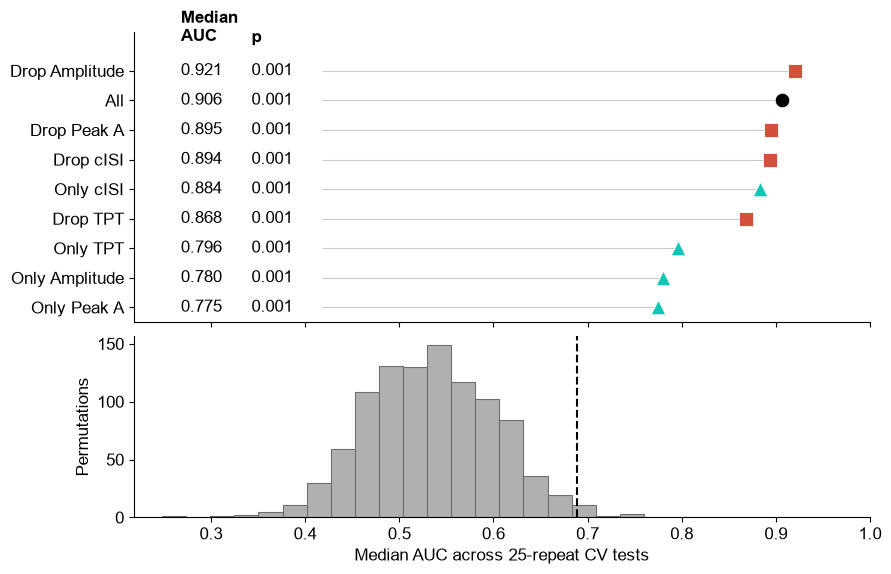

Saved output\figures\S5\S5_feature_ablation_with_labels.png
Saved output\figures\S5\S5_feature_ablation_with_labels.svg
Saved output\figures\S5\S5_feature_ablation_with_labels.pdf
Saved output\figures\S5\S5_feature_ablation_without_labels.png
Saved output\figures\S5\S5_feature_ablation_without_labels.svg
Saved output\figures\S5\S5_feature_ablation_without_labels.pdf
Saved output\figures\S5\S5_feature_ablation_forest.csv
Saved output\figures\S5\S5_feature_ablation_null.csv


In [9]:
forest_results = forest_data.rename(
    columns={'median_auc': 'median_value', 'permutation_p_value': 'p_value'}
).to_dict('records')
fig = draw_ablation_forest_figure(forest_results, null_auc, hist_bins=20)
with paper_style_context():
    saved_paths = save_label_variants(fig, OUTPUT_DIR, FIGURE_STEM, dpi=300)
plt.show()
report_saved([*saved_paths, FOREST_CSV_PATH, NULL_CSV_PATH])